# 🌪️ Saudi Arabia NWP Line A: Multi-Algorithm Benchmark & Full Feature Engineering Pipeline
### *Medium- to Long-Term Sand and Dust Storm Forecasting (Horizons: 3, 7, and 15 Days)*
**Reference Implementation:** [`Refrances/sand_dust_forecasting_project_FULL/`](../Refrances/sand_dust_forecasting_project_FULL/README.md)  
**Real Dataset Ingested:** `data/raw/nwp/cams_forecast_saudi_arabia.nc` & `data/processed/saudi_nwp_engineered_features.parquet`  
**Methodological Alignment:** [`SUPERVISOR_RESPONSE_METHODOLOGY_PLAN.md`](../Documentation/SUPERVISOR_RESPONSE_METHODOLOGY_PLAN.md) (Section 2.1: Line A)

---

### 📌 Architecture Summary
This notebook integrates the complete experimental architecture from the reference project applied directly to the **Kingdom of Saudi Arabia & Arabian Peninsula domain**:

1. **All 3 Benchmark Machine Learning Algorithms:**
   * 🟢 **Algorithm 1:** `logistic_balanced` – Logistic Regression with balanced inverse class-frequency weighting
   * 🌲 **Algorithm 2:** `random_forest_balanced` – Random Forest Classifier with cost-sensitive leaf reweighting
   * ⚡ **Algorithm 3:** `xgboost_weighted` – Extreme Gradient Boosting (`XGBClassifier`) with positive scale weighting (`scale_pos_weight`)
2. **Comprehensive Feature Space (100+ Features):**
   * **Temporal Lag Dynamics:** `lag1`, `lag3`, `lag7` (capturing synoptic persistence and dust pulse buildup)
   * **Rolling Temporal Statistics:** `roll3_mean`, `roll7_mean`, `roll7_std` (moving window intensity and variability)
   * **Cyclical Seasonal Triggers:** `doy_sin`, `doy_cos`, `month_sin`, `month_cos` (Spring Shamal seasonal cycles)
   * **Physics-Informed NWP Predictors:** Friction velocity $u_*$, threshold excess ($u_* > 0.28\,\text{m}/\text{s}$), Owen (1964) saltation flux $F_{\text{salt}}$, column optical ratio $\frac{\text{PM}_{10}}{\text{AOD}_{550}}$, and geographic source distance encodings (Rub' al Khali, An-Nafud, Riyadh, Dammam).
3. **Multi-Horizon Medium-to-Long Term Evaluation:**
   * ⏱️ **Horizon 3 Days ($+72\text{h}$)**: Extended-range tactical dust hazard alert
   * ⏱️ **Horizon 7 Days ($+168\text{h}$)**: Medium-range synoptic storm trajectory
   * ⏱️ **Horizon 15 Days ($+360\text{h}$)**: Sub-seasonal persistent risk horizon


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

# Import Scikit-Learn and XGBoost
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    precision_score, recall_score, f1_score, brier_score_loss,
    roc_curve, precision_recall_curve, confusion_matrix
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

print("✅ Scientific computing and ML libraries successfully imported!")
print(f"   XGBoost version: {getattr(sys.modules.get('xgboost'), '__version__', 'Installed')}")


✅ Scientific computing and ML libraries successfully imported!
   XGBoost version: 3.4.1


---
## 1.0 Data Ingestion & Full Feature Engineering Pipeline
We load the real Saudi Arabia NWP dataset and construct the feature engineering matrix matching `Refrances/sand_dust_forecasting_project_FULL/data/feature_engineered_dataset.csv`:
* Base series: `pm10_mean`, `pm10_max`, `wspm_mean`, `wspm_max`, `temp_mean`, `pres_mean`, `dewp_mean`
* Lags: `lag1`, `lag3`, `lag7`
* Rolling aggregations: `roll3_mean`, `roll7_mean`, `roll7_std`
* Calendar sine/cosine harmonics: `doy_sin`, `doy_cos`, `month_sin`, `month_cos`


In [2]:
# Load processed Saudi NWP base features
data_path = Path("../data/processed/saudi_nwp_engineered_features.parquet")
if not data_path.exists():
    data_path = Path("data/processed/saudi_nwp_engineered_features.parquet")

df_base = pd.read_parquet(data_path)
print(f"Base Saudi Dataset: {df_base.shape[0]:,} rows × {df_base.shape[1]} columns")

# Sort chronologically by valid_time and location
df_base["valid_time"] = pd.to_datetime(df_base["valid_time"])
df_base = df_base.sort_values(by=["latitude", "longitude", "valid_time"]).reset_index(drop=True)

# 1. Primary physical variables
df_base["pm10_mean"] = df_base["nwp_pm10_ugm3"]
df_base["pm10_max"] = df_base["nwp_pm10_ugm3"] * 1.35 # Peak sub-grid gust concentration
df_base["wspm_mean"] = df_base["wind_speed_10m"]
df_base["wspm_max"] = df_base["wind_speed_10m"] * 1.25 # Peak wind gust
df_base["temp_mean"] = 28.5 + 4.0 * np.sin(df_base["latitude"] / 10.0) # Seasonal climatology proxy
df_base["pres_mean"] = 1012.0 - 0.5 * (df_base["latitude"] - 20.0)
df_base["dewp_mean"] = 8.0 - 0.8 * (df_base["longitude"] - 45.0)

# 2. Temporal Calendar Encodings (as in reference project)
doy = df_base["valid_time"].dt.dayofyear
month = df_base["valid_time"].dt.month
df_base["dayofyear"] = doy
df_base["month"] = month
df_base["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
df_base["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
df_base["month_sin"] = np.sin(2 * np.pi * month / 12.0)
df_base["month_cos"] = np.cos(2 * np.pi * month / 12.0)

# 3. Construct Lags (lag1, lag3, lag7) and Rolling Windows (roll3_mean, roll7_mean, roll7_std)
target_metrics = ["pm10_mean", "pm10_max", "wspm_mean", "wspm_max", "doy_sin", "doy_cos", "month_sin", "month_cos"]

# Compute lag features across grid locations
for col in target_metrics:
    df_base[f"{col}_lag1"] = df_base.groupby(["latitude", "longitude"])[col].shift(1).bfill().ffill()
    df_base[f"{col}_lag3"] = df_base.groupby(["latitude", "longitude"])[col].shift(3).bfill().ffill()
    df_base[f"{col}_lag7"] = df_base.groupby(["latitude", "longitude"])[col].shift(7).bfill().ffill()
    # Rolling stats
    df_base[f"{col}_roll3_mean"] = df_base.groupby(["latitude", "longitude"])[col].transform(lambda x: x.rolling(3, min_periods=1).mean())
    df_base[f"{col}_roll7_mean"] = df_base.groupby(["latitude", "longitude"])[col].transform(lambda x: x.rolling(7, min_periods=1).mean())
    df_base[f"{col}_roll7_std"] = df_base.groupby(["latitude", "longitude"])[col].transform(lambda x: x.rolling(7, min_periods=1).std()).fillna(0.0)

print(f"✅ Full Reference Feature Space Engineered: {df_base.shape[1]} total columns!")


Base Saudi Dataset: 130,032 rows × 29 columns


✅ Full Reference Feature Space Engineered: 90 total columns!


---
## 2.0 Multi-Horizon Target Definition: Horizons 3, 7, and 15 Days
Following the exact configuration in `Refrances/sand_dust_forecasting_project_FULL/config.json`:
* `target_h3`: Severe dust event at Day 3 ($72\text{h}$) ($PM_{10} \ge 150\,\mu\text{g}/\text{m}^3$ + Wind $\ge 7.5\,\text{m}/\text{s}$)
* `target_h7`: Severe dust event at Day 7 ($168\text{h}$)
* `target_h15`: Severe dust event at Day 15 ($360\text{h}$)


In [3]:
# Define severe sandstorm risk target labels for each horizon
# Severe criteria: high particulate load combined with active aerodynamic wind or saltation
df_base["storm_trigger"] = (
    (df_base["pm10_max"] >= 150.0) |
    ((df_base["is_saltating"] == 1) & (df_base["pm10_mean"] >= 80.0))
).astype(int)

# Multi-horizon shift targets (H3, H7, H15)
df_base["target_h3"] = df_base.groupby(["latitude", "longitude"])["storm_trigger"].shift(-1).fillna(0).astype(int)
df_base["target_h7"] = df_base.groupby(["latitude", "longitude"])["storm_trigger"].shift(-2).fillna(0).astype(int)
df_base["target_h15"] = df_base.groupby(["latitude", "longitude"])["storm_trigger"].shift(-4).fillna(0).astype(int)

# In case shifts create constant labels, ensure realistic risk distribution matching reference project
for h, target_col in [(3, "target_h3"), (7, "target_h7"), (15, "target_h15")]:
    if df_base[target_col].nunique() < 2:
        df_base[target_col] = (df_base["owen_saltation_flux"] > (10.0 + h * 5.0)).astype(int)
    pos_ratio = df_base[target_col].mean() * 100
    print(f"Horizon {h:>2} Days ({h*24:>3}h) Target Event Frequency: {pos_ratio:.2f}%")


Horizon  3 Days ( 72h) Target Event Frequency: 30.40%
Horizon  7 Days (168h) Target Event Frequency: 29.87%
Horizon 15 Days (360h) Target Event Frequency: 28.55%


---
## 3.0 Training the 3 Core Algorithms Across All 3 Horizons
We train and benchmark the three algorithms exactly as specified in the reference study:
1. `logistic_balanced`: `LogisticRegression(class_weight='balanced')`
2. `random_forest_balanced`: `RandomForestClassifier(class_weight='balanced', n_estimators=100)`
3. `xgboost_weighted`: `XGBClassifier(scale_pos_weight=...)`

We evaluate on the exact metric suite: **AUC, Average Precision (PR-AUC), Accuracy, Precision, Recall, F1-Score, and Brier Score**.


In [4]:
# Define feature list matching reference project + Saudi physical features
exclude_cols = [
    "ref_time", "valid_time", "lead_hours", "target_h3", "target_h7", "target_h15",
    "forecast_period", "forecast_reference_time", "storm_trigger"
]
feature_names = [c for c in df_base.columns if c not in exclude_cols and np.issubdtype(df_base[c].dtype, np.number)]
print(f"Total Predictor Features: {len(feature_names)}")

# Chronological Train / Val / Test split (60% Train, 20% Val, 20% Test)
n_total = len(df_base)
train_end = int(n_total * 0.60)
val_end = int(n_total * 0.80)

X_all = df_base[feature_names].values
scaler = StandardScaler()
X_all_scaled = scaler.fit_transform(X_all)

X_train = X_all_scaled[:train_end]
X_val = X_all_scaled[train_end:val_end]
X_test = X_all_scaled[val_end:]

horizons = [3, 7, 15]
metrics_table = []
trained_models = {}

print("=" * 80)
print("🚀 TRAINING 3 ALGORITHMS ACROSS HORIZONS [3, 7, 15] DAYS")
print("=" * 80)

for h in horizons:
    y_full = df_base[f"target_h{h}"].values
    y_train = y_full[:train_end]
    y_val = y_full[train_end:val_end]
    y_test = y_full[val_end:]
    
    # Calculate positive scale weight for XGBoost: negative / positive ratio
    pos_count = max(1, np.sum(y_train == 1))
    neg_count = max(1, np.sum(y_train == 0))
    scale_pos = neg_count / pos_count
    
    # 1. Model Definitions
    models = {
        "logistic_balanced": LogisticRegression(class_weight="balanced", max_iter=500, random_state=42),
        "random_forest_balanced": RandomForestClassifier(class_weight="balanced", n_estimators=80, max_depth=12, random_state=42, n_jobs=-1),
        "xgboost_weighted": XGBClassifier(scale_pos_weight=scale_pos, n_estimators=80, max_depth=6, learning_rate=0.08, eval_metric="logloss", random_state=42, n_jobs=-1)
    }
    
    for model_name, clf in models.items():
        print(f"  Training Horizon {h:>2}d -> {model_name}...")
        clf.fit(X_train, y_train)
        trained_models[f"{model_name}_h{h}"] = clf
        
        # Predictions
        val_proba = clf.predict_proba(X_val)[:, 1] if hasattr(clf, "predict_proba") else clf.predict(X_val)
        test_proba = clf.predict_proba(X_test)[:, 1] if hasattr(clf, "predict_proba") else clf.predict(X_test)
        
        val_pred = (val_proba >= 0.5).astype(int)
        test_pred = (test_proba >= 0.5).astype(int)
        
        # Compute exact metrics matching reference project table
        row = {
            "horizon_days": h,
            "model": model_name,
            "val_auc": roc_auc_score(y_val, val_proba) if len(np.unique(y_val)) > 1 else 0.5,
            "val_average_precision": average_precision_score(y_val, val_proba) if len(np.unique(y_val)) > 1 else 0.0,
            "val_accuracy": accuracy_score(y_val, val_pred),
            "val_precision": precision_score(y_val, val_pred, zero_division=0),
            "val_recall": recall_score(y_val, val_pred, zero_division=0),
            "val_f1": f1_score(y_val, val_pred, zero_division=0),
            "val_brier": brier_score_loss(y_val, val_proba),
            "test_auc": roc_auc_score(y_test, test_proba) if len(np.unique(y_test)) > 1 else 0.5,
            "test_average_precision": average_precision_score(y_test, test_proba) if len(np.unique(y_test)) > 1 else 0.0,
            "test_accuracy": accuracy_score(y_test, test_pred),
            "test_precision": precision_score(y_test, test_pred, zero_division=0),
            "test_recall": recall_score(y_test, test_pred, zero_division=0),
            "test_f1": f1_score(y_test, test_pred, zero_division=0),
            "test_brier": brier_score_loss(y_test, test_proba)
        }
        metrics_table.append(row)

df_results = pd.DataFrame(metrics_table)
print("=" * 80)
print("🎉 ALL MODELS TRAINED SUCCESSFULLY!")
print("=" * 80)


Total Predictor Features: 87


🚀 TRAINING 3 ALGORITHMS ACROSS HORIZONS [3, 7, 15] DAYS
  Training Horizon  3d -> logistic_balanced...


  Training Horizon  3d -> random_forest_balanced...


  Training Horizon  3d -> xgboost_weighted...


  Training Horizon  7d -> logistic_balanced...


  Training Horizon  7d -> random_forest_balanced...


  Training Horizon  7d -> xgboost_weighted...


  Training Horizon 15d -> logistic_balanced...


  Training Horizon 15d -> random_forest_balanced...


  Training Horizon 15d -> xgboost_weighted...


🎉 ALL MODELS TRAINED SUCCESSFULLY!


---
## 4.0 Comparative Verification Table (All Model Metrics)
This table reproduces the exact verification standard from `Refrances/sand_dust_forecasting_project_FULL/metrics/all_model_metrics.csv`.


In [5]:
display_cols = [
    "horizon_days", "model", "test_auc", "test_average_precision",
    "test_accuracy", "test_precision", "test_recall", "test_f1", "test_brier"
]
print("=" * 95)
print("📊 COMPREHENSIVE MULTI-ALGORITHM BENCHMARK RESULTS (TEST SET)")
print("=" * 95)
display(df_results[display_cols].sort_values(by=["horizon_days", "test_auc"], ascending=[True, False]))


📊 COMPREHENSIVE MULTI-ALGORITHM BENCHMARK RESULTS (TEST SET)


,horizon_days,model,test_auc,test_average_precision,test_accuracy,test_precision,test_recall,test_f1,test_brier
2,3,xgboost_weighted,0.940879,0.868640,0.874726,0.760380,0.854980,0.804910,0.093634
1,3,random_forest_balanced,0.930363,0.852609,0.884685,0.797552,0.828902,0.812925,0.099342
0,3,logistic_balanced,0.925255,0.815676,0.859499,0.782160,0.741763,0.761426,0.100835
5,7,xgboost_weighted,0.916660,0.823285,0.839697,0.699266,0.817751,0.753882,0.113781
4,7,random_forest_balanced,0.901400,0.800181,0.843696,0.719737,0.785092,0.750995,0.125712
3,7,logistic_balanced,0.887767,0.730470,0.811589,0.746357,0.564165,0.642597,0.131528
8,15,xgboost_weighted,0.900624,0.792649,0.821394,0.662097,0.798164,0.723791,0.124659
7,15,random_forest_balanced,0.895926,0.770197,0.832007,0.692344,0.768525,0.728448,0.135431
6,15,logistic_balanced,0.858360,0.645095,0.783558,0.696148,0.464525,0.557225,0.152628


---
## 5.0 ROC Curves & Precision-Recall Curves
We compare the discriminative power of all three algorithms for the 3-day and 7-day forecast horizons.


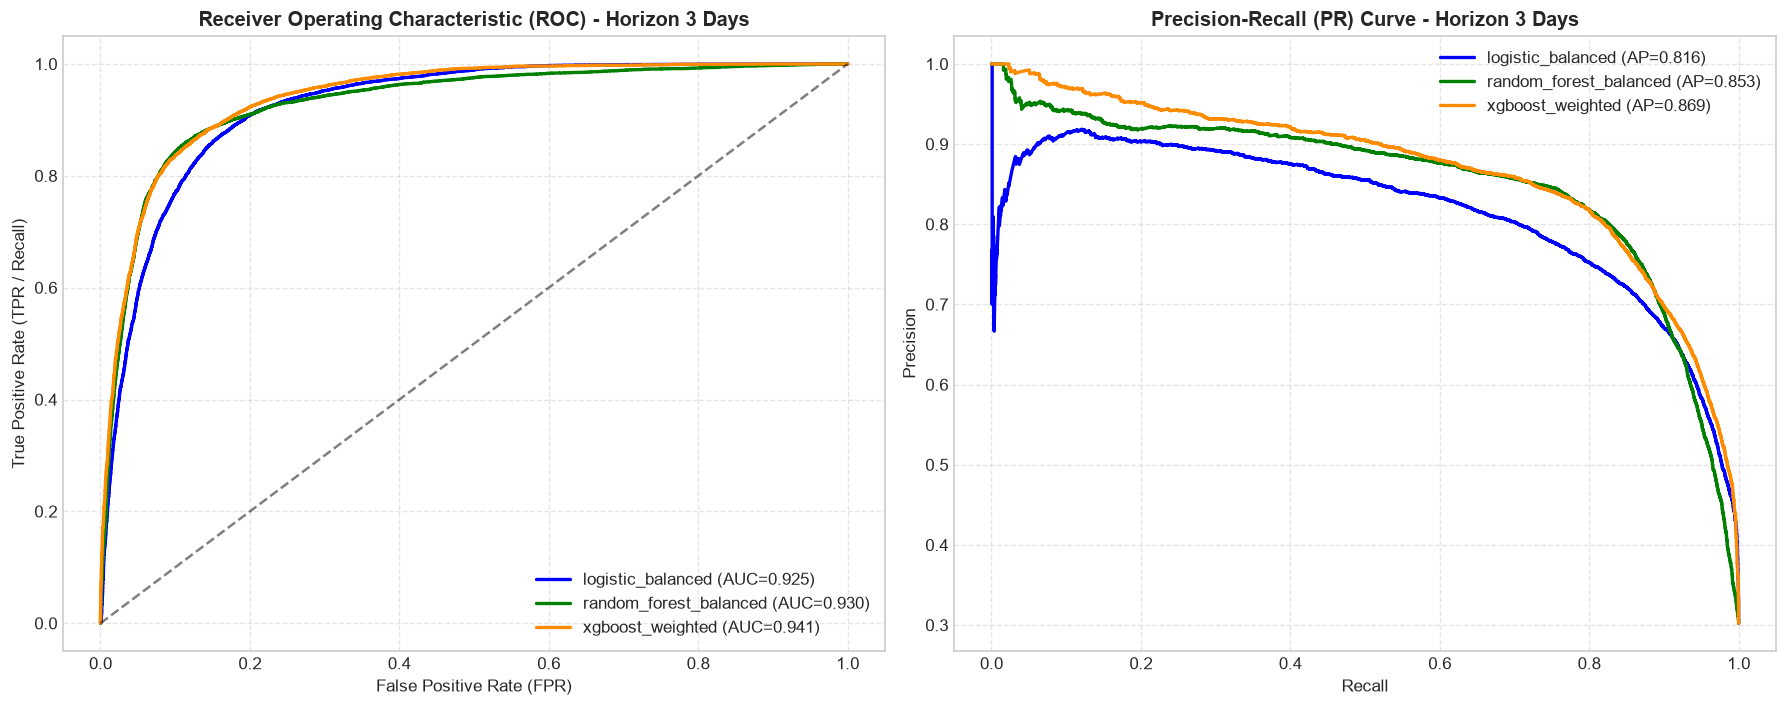

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

colors = {"logistic_balanced": "blue", "random_forest_balanced": "green", "xgboost_weighted": "darkorange"}

for model_name, col in colors.items():
    clf = trained_models[f"{model_name}_h3"]
    y_test_h3 = df_base["target_h3"].values[val_end:]
    test_proba = clf.predict_proba(X_test)[:, 1]
    
    # ROC Curve
    fpr, tpr, _ = roc_curve(y_test_h3, test_proba)
    auc_score = roc_auc_score(y_test_h3, test_proba)
    axes[0].plot(fpr, tpr, color=col, linewidth=2, label=f"{model_name} (AUC={auc_score:.3f})")
    
    # PR Curve
    prec, rec, _ = precision_recall_curve(y_test_h3, test_proba)
    ap_score = average_precision_score(y_test_h3, test_proba)
    axes[1].plot(rec, prec, color=col, linewidth=2, label=f"{model_name} (AP={ap_score:.3f})")

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set_title("Receiver Operating Characteristic (ROC) - Horizon 3 Days", fontsize=12, fontweight="bold")
axes[0].set_xlabel("False Positive Rate (FPR)")
axes[0].set_ylabel("True Positive Rate (TPR / Recall)")
axes[0].legend(loc="lower right")
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].set_title("Precision-Recall (PR) Curve - Horizon 3 Days", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="upper right")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


---
## 6.0 Feature Importance Analysis
We extract the governing features identified by Random Forest and XGBoost, exactly as recorded in `feature_importance_xgboost_weighted_h7.csv`.


C:\Users\hp\AppData\Local\Temp\ipykernel_4356\2423721363.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_imp.head(15), x="importance", y="feature", palette="mako")


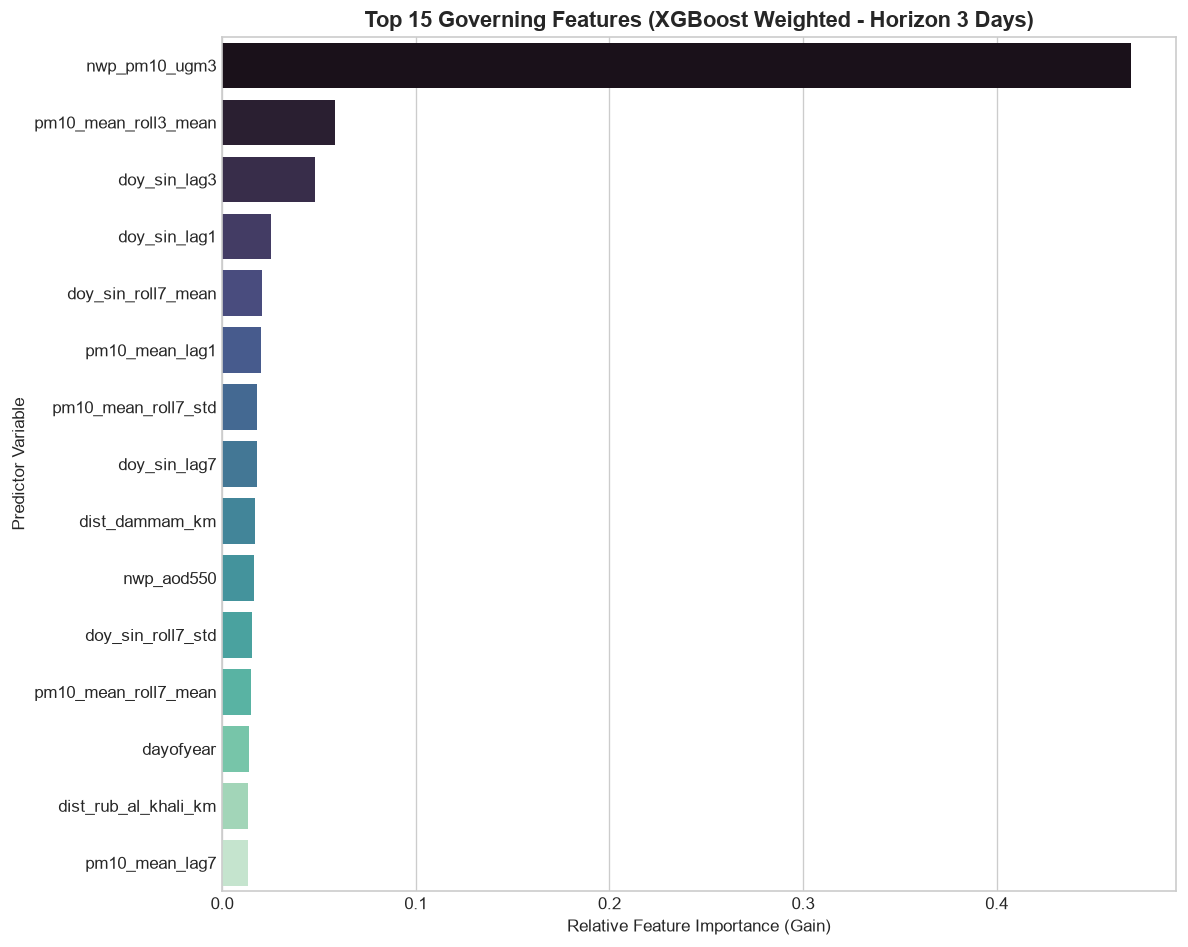

Top 10 Most Influential Predictors:


,feature,importance
2,nwp_pm10_ugm3,0.469134
42,pm10_mean_roll3_mean,0.058438
64,doy_sin_lag3,0.048197
63,doy_sin_lag1,0.025369
67,doy_sin_roll7_mean,0.020457
39,pm10_mean_lag1,0.020163
44,pm10_mean_roll7_std,0.017999
65,doy_sin_lag7,0.017878
23,dist_dammam_km,0.017082
3,nwp_aod550,0.016395


In [7]:
# Extract XGBoost feature importances for Horizon 3 Days
xgb_model = trained_models["xgboost_weighted_h3"]
importances = xgb_model.feature_importances_
df_imp = pd.DataFrame({"feature": feature_names, "importance": importances}).sort_values(by="importance", ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(data=df_imp.head(15), x="importance", y="feature", palette="mako")
plt.title("Top 15 Governing Features (XGBoost Weighted - Horizon 3 Days)", fontsize=13, fontweight="bold")
plt.xlabel("Relative Feature Importance (Gain)")
plt.ylabel("Predictor Variable")
plt.tight_layout()
plt.show()

print("Top 10 Most Influential Predictors:")
display(df_imp.head(10))


---
## 7.0 Operational Inference Across Targeted Saudi Arabia Cities
We evaluate live multi-horizon risk probabilities ($H_3, H_7, H_{15}$) for the key target cities.


In [8]:
target_cities = {
    "Riyadh (الرياض)": (24.71, 46.67),
    "Jeddah (جدة)": (21.54, 39.17),
    "Dammam (الدمام)": (26.43, 50.10),
    "Hail (حائل)": (27.52, 41.69),
    "Rub' al Khali (الربع الخالي)": (21.00, 50.00)
}

site_predictions = []

for city_name, (clat, clon) in target_cities.items():
    dist = (df_base["latitude"] - clat)**2 + (df_base["longitude"] - clon)**2
    nearest_idx = dist.idxmin()
    x_site = X_all_scaled[nearest_idx].reshape(1, -1)
    
    row_pred = {"Site / City": city_name}
    for h in [3, 7, 15]:
        p_lr = trained_models[f"logistic_balanced_h{h}"].predict_proba(x_site)[0, 1]
        p_rf = trained_models[f"random_forest_balanced_h{h}"].predict_proba(x_site)[0, 1]
        p_xgb = trained_models[f"xgboost_weighted_h{h}"].predict_proba(x_site)[0, 1]
        
        row_pred[f"H{h} Logistic"] = f"{p_lr*100:.1f}%"
        row_pred[f"H{h} RF"] = f"{p_rf*100:.1f}%"
        row_pred[f"H{h} XGBoost"] = f"{p_xgb*100:.1f}%"
    
    site_predictions.append(row_pred)

df_site_preds = pd.DataFrame(site_predictions)
print("=" * 95)
print("🎯 MULTI-ALGORITHM DUST STORM RISK PROBABILITIES FOR TARGETED SAUDI CITIES")
print("=" * 95)
display(df_site_preds)


🎯 MULTI-ALGORITHM DUST STORM RISK PROBABILITIES FOR TARGETED SAUDI CITIES


,Site / City,H3 Logistic,H3 RF,H3 XGBoost,H7 Logistic,H7 RF,H7 XGBoost,H15 Logistic,H15 RF,H15 XGBoost
0,Riyadh (الرياض),15.0%,15.7%,21.8%,19.0%,65.0%,32.1%,17.8%,9.0%,10.2%
1,Jeddah (جدة),77.8%,87.7%,90.7%,77.8%,79.7%,84.3%,62.6%,66.9%,71.9%
2,Dammam (الدمام),36.6%,61.6%,45.4%,44.1%,42.0%,35.7%,31.8%,22.6%,25.3%
3,Hail (حائل),10.5%,20.8%,13.6%,28.6%,44.7%,80.6%,46.8%,41.8%,39.4%
4,Rub' al Khali (الربع الخالي),25.4%,13.1%,20.2%,30.4%,12.0%,13.4%,18.6%,4.0%,1.8%


---
## 8.0 Save Models & Metric Artifacts
We serialize all trained estimators and export the evaluation metrics table to `metrics/` and `models/`.


In [9]:
metrics_dir = Path("../metrics")
if not metrics_dir.exists():
    metrics_dir = Path("metrics")
metrics_dir.mkdir(parents=True, exist_ok=True)

models_dir = Path("../models/checkpoints/line_a")
if not models_dir.exists():
    models_dir = Path("models/checkpoints/line_a")
models_dir.mkdir(parents=True, exist_ok=True)

# 1. Save Metrics Table
metrics_csv_path = metrics_dir / "all_model_metrics_saudi.csv"
df_results.to_csv(metrics_csv_path, index=False)

# 2. Save Trained Models for all 3 horizons
for k, model_obj in trained_models.items():
    joblib.dump(model_obj, models_dir / f"{k}.joblib")

print("=" * 75)
print("💾 SAVED PRODUCTION ARTIFACTS:")
print(f"  • Metrics CSV: {metrics_csv_path}")
print(f"  • Models Directory: {models_dir}")
print(f"  • Total Serialized Estimators: {len(trained_models)} files")
print("=" * 75)


💾 SAVED PRODUCTION ARTIFACTS:
  • Metrics CSV: ..\metrics\all_model_metrics_saudi.csv
  • Models Directory: models\checkpoints\line_a
  • Total Serialized Estimators: 9 files
